# 05 · Modelo de PD (probabilidad de impago)

**Objetivo:** encontrar el mejor modelo para estimar la **probabilidad de que un préstamo acabe en impago** y entrenarlo con todo el conjunto de entrenamiento:
1. Fijar el listón: el **subrating** de Lending Club.
2. Preparar un ***pipeline*** (preparación de `04_scripts/preparacion.py` + preprocesado + modelo) y la **validación cruzada**.
3. Hacer una **búsqueda en rejilla** (`GridSearchCV`) que compara a la vez **tipos de modelo** (regresión logística y *gradient boosting*) y sus **hiperparámetros**.
4. Elegir el modelo con una regla explícita, analizarlo (discriminación, calibración, importancia de variables) y guardarlo.

**Cómo se trabaja** (igual que en los notebooks anteriores): observación → decisión → aplicación. Cada decisión aparece en un recuadro **Decisión Dx**.

> **Regla general:** el conjunto de **validación** (30 %, notebook 01) **no se toca** en este notebook. Todas las comparaciones se hacen con validación cruzada dentro de entrenamiento; la validación se reserva para la evaluación final de los tres modelos juntos.

<a id="s0"></a>

## Registro de decisiones

| # | Tema | Decisión | Motivo principal |
|---|---|---|---|
| D1 | Listón | AUC del subrating de Lending Club | Es la evaluación profesional que el modelo debe igualar sin usar el tipo de interés |
| D2 | *Pipeline* | `PreparacionScoring` + `ColumnTransformer` (*one-hot* + estandarización) + modelo, todo en un objeto | La preparación y el preprocesado se aprenden solo en cada partición y viajan con el modelo a la API |
| D3 | Validación | Validación cruzada estratificada de 3 particiones, semilla 42 | Estimación estable sin tocar el conjunto de validación |
| D4 | Métricas | AUC para elegir; *log-loss* y Brier para vigilar la calibración | La pérdida esperada usa la probabilidad, no solo el orden |
| D5 | Búsqueda | `GridSearchCV` con 8 logísticas y 12 *gradient boosting* | Compara familias de modelo e hiperparámetros con las mismas particiones |
| D6 | Elección | Regla de un error estándar | Entre modelos empatados, el más sencillo |
| D7 | `sector_empleo` | Mantener `sector_empleo` | Quitarla cuesta 0,003 de AUC, tres veces su error estándar |
| D8 | Calibración | No recalibrar | La PD predicha coincide con la tasa real en todos los deciles (diferencia ≤ 0,007) |
| D9 | Guardado | `05_modelos/modelo_pd.pkl` con `cloudpickle`: el *pipeline*, las variables y las métricas | La API y la validación final cargan el mismo objeto, sin necesitar `preparacion.py` |

## Índice

- [Registro de decisiones](#s0)
- [1 · Importar librerías](#s1)
- [2 · Cargar los datos](#s2)
- [3 · Listón: el subrating (D1)](#s3)
- [4 · Pipeline de preprocesado y modelo (D2)](#s4)
- [5 · Validación cruzada y métricas (D3, D4)](#s5)
- [6 · Búsqueda del mejor modelo (D5)](#s6)
  - [6.1 · Resultados de la búsqueda](#s6-1)
  - [6.2 · Efecto de los hiperparámetros](#s6-2)
- [7 · Elección del modelo (D6)](#s7)
- [8 · ¿Hace falta `sector_empleo`? (D7)](#s8)
- [9 · Análisis del modelo elegido](#s9)
  - [9.1 · Discriminación: AUC, Gini y KS](#s9-1)
  - [9.2 · Calibración (D8)](#s9-2)
  - [9.3 · Importancia de las variables](#s9-3)
  - [9.4 · Sentido de las variables](#s9-4)
- [10 · Entrenar y guardar el modelo final (D9)](#s10)
- [11 · Resumen y próximos pasos](#s11)

> Cada sección empieza con una **franja azul**. Debajo de cada resultado hay una explicación de **qué se hace** y **qué se observa**.

<a id="s1"></a>
<div style="background-color:#1f4e79; padding:2px 16px; border-radius:6px; margin-top:16px;">

## <span style="color:#ffffff">1 · IMPORTAR LIBRERÍAS</span>

</div>

In [37]:
# --- Librerías generales ----------------------------------------------------
from pathlib import Path          # rutas de archivos independientes del sistema operativo
import sys                        # añadir la carpeta 04_scripts a las rutas de Python
import time                       # medir cuánto tarda la búsqueda
import tempfile, shutil           # carpeta temporal para la caché del pipeline (y borrarla al final)
import warnings                   # silenciar avisos de convergencia repetidos
import cloudpickle                # guardar el modelo entrenado junto con el código de preparacion.py
import numpy as np                # cálculo numérico
import pandas as pd               # manejo de tablas (DataFrames)
import matplotlib.pyplot as plt   # gráficos
import seaborn as sns             # gráficos estadísticos sobre matplotlib
import sklearn                    # para guardar la versión con el modelo

# --- Preparación de los datos (04_scripts/preparacion.py) --------------------
sys.path.insert(0, '../../04_scripts')   # la carpeta del módulo, relativa a 03_notebooks/es
import preparacion                       # el módulo completo (se necesita para guardarlo con el modelo)
from preparacion import (PreparacionScoring,   # transformador: limpieza, imputación, variables nuevas, recortes y logaritmos
                         preparar_conjunto,    # población del modelo y objetivos (impago, EAD, LGD)
                         COLUMNAS_ENTRADA,     # columnas originales que recibe el pipeline
                         CATEGORICAS, NUMERICAS, VARIABLES_PD)  # variables que salen de la preparación

# --- Preprocesado y pipeline -------------------------------------------------
from sklearn.compose import ColumnTransformer                    # tratar distinto cada grupo de columnas
from sklearn.preprocessing import OneHotEncoder, StandardScaler  # codificar categóricas y estandarizar numéricas
from sklearn.pipeline import Pipeline                            # encadenar preprocesado y modelo
from sklearn.base import clone                                   # copia sin entrenar de un modelo

# --- Modelos -----------------------------------------------------------------
from sklearn.linear_model import LogisticRegression              # regresión logística (con L1 o L2)
from sklearn.ensemble import HistGradientBoostingClassifier      # gradient boosting por histogramas

# --- Validación, búsqueda y métricas -------------------------------------------
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_predict, cross_validate
from sklearn.metrics import roc_auc_score, roc_curve, log_loss, brier_score_loss
from sklearn.inspection import permutation_importance, PartialDependenceDisplay

# --- Opciones de visualización ------------------------------------------------
pd.set_option('display.float_format', lambda x: '%.4f' % x)  # 4 decimales: las diferencias entre modelos son pequeñas
pd.set_option('display.max_columns', 60)                     # mostrar todas las columnas
pd.set_option('display.max_colwidth', 120)                   # ver los hiperparámetros completos
sns.set_theme(style='whitegrid')                             # estilo de los gráficos
warnings.filterwarnings('ignore', category=UserWarning)      # avisos de categorías desconocidas en las particiones
warnings.filterwarnings('ignore', category=FutureWarning)

print(f"✅ Librerías importadas correctamente (scikit-learn {sklearn.__version__})")

✅ Librerías importadas correctamente (scikit-learn 1.9.1)


**Qué se hace:** se importan las librerías: las de preprocesado y *pipeline*, los dos tipos de modelo que se van a comparar, las herramientas de validación, búsqueda y métricas, y el módulo `04_scripts/preparacion.py` con la preparación de los datos (notebooks 02–04 en un solo sitio).

**Qué se observa:** el mensaje confirma que todo está instalado y muestra la versión de `scikit-learn`. La versión importa: un modelo guardado con una versión puede no cargarse con otra, por eso se guarda junto al modelo (sección 10).

<a id="s2"></a>
<div style="background-color:#1f4e79; padding:2px 16px; border-radius:6px; margin-top:16px;">

## <span style="color:#ffffff">2 · CARGAR LOS DATOS</span>

</div>

In [38]:
# Rutas de entrada (relativas a la carpeta de este notebook: 03_notebooks/es)
RUTA_DATOS = Path('../../02_datos/03_Entrenamiento')
RUTA_MODELOS = Path('../../05_modelos')   # carpeta donde se guardan los modelos entrenados

# Conjunto de entrenamiento ORIGINAL (notebook 01) con la población del modelo y los objetivos (preparar_conjunto)
df = preparar_conjunto(pd.read_pickle(RUTA_DATOS / 'train.pkl'))

# X = columnas originales que necesita la preparación · y = objetivo (1 = impago)
# La limpieza, las imputaciones y las transformaciones las hace el primer paso del pipeline (sección 4)
X = df[COLUMNAS_ENTRADA]
y = df['impago']

print(f"Préstamos: {X.shape[0]:,} · Columnas de entrada: {X.shape[1]}")
print(f"Variables tras la preparación: {len(VARIABLES_PD)} ({len(CATEGORICAS)} categóricas y {len(NUMERICAS)} numéricas)")
print(f"Tasa de impago: {y.mean():.2%}")

Préstamos: 443,405 · Columnas de entrada: 19
Variables tras la preparación: 15 (4 categóricas y 11 numéricas)
Tasa de impago: 14.85%


**Qué se hace:** se carga el conjunto de entrenamiento **original** y `preparar_conjunto()` quita las viviendas fuera de la población (NONE, OTHER, ANY) y calcula el objetivo `impago`. `X` son las 19 columnas originales que necesita la preparación: ya no se parte del tablón del notebook 04, porque esa preparación ahora va **dentro del *pipeline***.

**Qué se observa:** **443.405 préstamos** y una tasa de impago del **14,85 %**: los mismos que el tablón del notebook 04. Las 19 columnas originales se convertirán en 15 variables (4 categóricas y 11 numéricas) dentro del *pipeline*.

<a id="s3"></a>
<div style="background-color:#1f4e79; padding:2px 16px; border-radius:6px; margin-top:16px;">

## <span style="color:#ffffff">3 · LISTÓN: EL SUBRATING (D1)</span>

</div>

El **subrating** (A1, A2... G5) es la nota que Lending Club asignaba a cada préstamo con su propio modelo. Ordenado de mejor a peor, sirve como "modelo" ya hecho: si se usa como puntuación, ¿qué AUC tiene?

El **AUC** (glosario del README) es la probabilidad de que, tomando al azar un préstamo impagado y uno pagado, el modelo dé más riesgo al impagado. 0,5 es azar y 1 es perfecto.

In [39]:
# El subrating es una categoría ordenada (A1 < A2 < ... < G5): sus códigos 0, 1, 2... crecen con el riesgo
puntuacion_subrating = df['subrating'].cat.codes
AUC_SUBRATING = roc_auc_score(y, puntuacion_subrating)

print(f"AUC del subrating de Lending Club: {AUC_SUBRATING:.4f} · Gini: {2 * AUC_SUBRATING - 1:.4f}")

AUC del subrating de Lending Club: 0.6687 · Gini: 0.3373


**Qué se hace:** se usa la posición del subrating (0 para A1, 1 para A2...) como puntuación de riesgo y se calcula su AUC. No se entrena nada, así que no hace falta validación cruzada.

**Qué se observa:** el subrating tiene un **AUC de 0,6687** (Gini 0,337). Es el listón: en 2 de cada 3 parejas impagado / pagado, Lending Club le daba peor nota al que impagó. Coincide con el 0,669 del notebook 03.

> **Decisión D1 · El listón del modelo es el AUC del subrating de Lending Club.**
> - **Por qué:** es una evaluación profesional hecha con más información de la que tenemos (por ejemplo, el historial completo del buró). Igualarla con las 15 variables del formulario ya sería un buen resultado.
> - **Por qué no se usa el subrating como variable:** el modelo debe funcionar para un cliente nuevo en la API, que no tiene subrating (notebook 03, D2). Además, el tipo de interés se fija a partir del subrating: usarlo sería copiar a Lending Club.

<a id="s4"></a>
<div style="background-color:#1f4e79; padding:2px 16px; border-radius:6px; margin-top:16px;">

## <span style="color:#ffffff">4 · PIPELINE DE PREPROCESADO Y MODELO (D2)</span>

</div>

Un ***pipeline*** encadena los pasos de preparación y el modelo en **un único objeto**. Cuando se entrena, cada paso aprende lo que necesita (por ejemplo, la media para estandarizar) **solo con los datos de entrenamiento** de ese momento; cuando se predice, aplica lo aprendido.

El *pipeline* tiene tres pasos:
1. **Preparación** (`PreparacionScoring`, de `04_scripts/preparacion.py`): limpieza (notebook 02), agrupaciones (03), imputaciones, variables nuevas, recortes y logaritmos (04). Las medianas y los límites de recorte se **aprenden en `fit()`** con los datos de entrenamiento de cada momento.
2. **Preprocesado** (`ColumnTransformer`, decidido en el notebook 04), con dos ramas:
   - **Categóricas → *one-hot*** (D9 del notebook 04): una columna 0 / 1 por categoría. Con `handle_unknown='ignore'`, una categoría nueva en la API no da error.
   - **Numéricas → estandarización** (D10 del notebook 04): media 0 y desviación 1, necesario para la regularización de la logística. A los árboles no les afecta.
3. **Modelo.**

**Caché (`memory`):** en la búsqueda, los dos primeros pasos son iguales para todas las combinaciones de una misma partición. Con una carpeta de caché, `scikit-learn` guarda su resultado la primera vez y lo reutiliza en vez de repetir la preparación 20 veces por partición.

In [40]:
# Carpeta temporal para la caché de los pasos de preparación y preprocesado (se borra en la sección 10)
CACHE = tempfile.mkdtemp(prefix='cache_pd_')

def crear_pipeline(modelo, categoricas=CATEGORICAS, numericas=NUMERICAS, parametros=None, cache=CACHE):
    """Devuelve un pipeline nuevo: preparación (preparacion.py) + preprocesado (one-hot + estandarización) + modelo.
    Si se pasan 'parametros' (por ejemplo, los de una combinación de la búsqueda), se aplican al pipeline.
    'cache' es la carpeta donde se reutilizan los pasos ya calculados (None = sin caché, para el modelo final)."""
    preprocesado = ColumnTransformer([
        ('categoricas', OneHotEncoder(handle_unknown='ignore'), categoricas),  # una columna por categoría
        ('numericas', StandardScaler(), numericas),                            # media 0 y desviación 1
    ])
    pipeline = Pipeline([
        ('preparacion', PreparacionScoring()),   # columnas originales -> 15 variables del modelo (+ principal)
        ('preprocesado', preprocesado),          # solo usa las variables indicadas
        ('modelo', modelo),
    ], memory=cache)
    if parametros is not None:
        pipeline.set_params(**parametros)
    return clone(pipeline)   # copia independiente: entrenar un pipeline no modifica a los demás

# Ejemplo: el pipeline con una regresión logística por defecto
pipeline_ejemplo = crear_pipeline(LogisticRegression())
pipeline_ejemplo

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preparacion', ...), ('preprocesado', ...), ...]"
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",'C:\\Users\\User\\AppDa...Temp\\cache_pd_79q6s5o9'
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,percentil_recorte,0.999
,tope_consultas,4.0
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categoricas', ...), ('numericas', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fi

**Qué se hace:** se define una función que construye el *pipeline* para cualquier modelo, y se muestra su estructura con una logística de ejemplo.

**Qué se observa:** el diagrama muestra los tres pasos: la preparación, el `ColumnTransformer` con sus dos ramas (categóricas y numéricas) y, después, el modelo. Este objeto es lo que se entrena, se evalúa y se guarda.

> **Decisión D2 · Preprocesado y modelo en un único *pipeline*.**
> - **Por qué:** en la validación cruzada, las medianas de imputación, los límites de recorte, el *one-hot* y la estandarización se aprenden solo con la parte de entrenamiento de cada partición, así que no se filtra información de la parte de evaluación.
> - **En la API:** se carga un solo objeto y se le pasan los datos del formulario **tal cual** (sector elegido en un desplegable, FICO, ingresos...); la preparación va dentro del modelo y no hay que repetirla a mano.
> - **Caché:** la preparación tarda unos segundos; sin caché se repetiría en cada una de las 60 evaluaciones de la búsqueda.
> - **Alternativa descartada:** preparar antes, en un tablón (como en el notebook 04). Es más sencillo de ver, pero los valores aprendidos se calculan con todo el entrenamiento (una pequeña fuga de información en la validación cruzada) y hay que guardarlos y aplicarlos por separado en la API.

<a id="s5"></a>
<div style="background-color:#1f4e79; padding:2px 16px; border-radius:6px; margin-top:16px;">

## <span style="color:#ffffff">5 · VALIDACIÓN CRUZADA Y MÉTRICAS (D3, D4)</span>

</div>

**Validación cruzada:** se parte el entrenamiento en 3 trozos; se entrena con 2 y se evalúa con el tercero, tres veces, cambiando el trozo de evaluación. El resultado es la media de las tres evaluaciones, y la **desviación típica** entre ellas dice cuánto varía por azar.

**Métricas:**
- **AUC:** cómo de bien **ordena** el modelo a los clientes por riesgo. Es la métrica principal.
- ***Log-loss*:** penaliza dar probabilidades equivocadas con mucha seguridad. Más bajo es mejor.
- **Brier:** el error cuadrático medio de la probabilidad (0 sería perfecto). Más bajo es mejor.

Las dos últimas miden la **calibración**: si el modelo dice 20 %, ¿impagan de verdad unos 20 de cada 100? Importa porque la pérdida esperada (PD × EAD × LGD) usa la probabilidad, no solo el orden.

In [41]:
# Particiones de la validación cruzada: 3 trozos con la misma tasa de impago (estratificadas) y semilla fija
PARTICIONES = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# Métricas que se calculan en cada partición. sklearn siempre maximiza, por eso las pérdidas van con signo negativo
METRICAS = {'AUC': 'roc_auc', 'log_loss': 'neg_log_loss', 'Brier': 'neg_brier_score'}

# Referencia de calibración: un modelo que dijera siempre la tasa media de impago
tasa = y.mean()
print(f"Log-loss de predecir siempre {tasa:.1%}: {log_loss(y, np.full(len(y), tasa)):.4f}")
print(f"Brier de predecir siempre {tasa:.1%}:    {brier_score_loss(y, np.full(len(y), tasa)):.4f}")

Log-loss de predecir siempre 14.8%: 0.4201
Brier de predecir siempre 14.8%:    0.1264


**Qué se hace:** se definen las particiones y las métricas, y se calculan el *log-loss* y el Brier de un modelo sin información (siempre la tasa media) como referencia.

**Qué se observa:** sin ninguna información, el *log-loss* es **0,4201** y el Brier **0,1264**. Un modelo útil tiene que bajar de esos valores.

> **Decisión D3 · Validación cruzada estratificada de 3 particiones con semilla 42.**
> - **Por qué 3 y no 5 o 10:** con 443.000 préstamos cada trozo tiene unos 148.000, suficiente para una evaluación estable; más particiones multiplicarían el tiempo de la búsqueda sin cambiar la elección.
> - **Por qué estratificada y con semilla:** misma tasa de impago en cada trozo y mismos resultados cada vez que se ejecuta. Son las mismas particiones que en los notebooks 03 y 04.
>
> **Decisión D4 · El AUC decide; el *log-loss* y el Brier vigilan la calibración.**
> - **Por qué el AUC:** es la métrica estándar en *scoring* y no depende de un umbral.
> - **Por qué vigilar la calibración:** dos modelos con el mismo AUC pueden dar probabilidades muy distintas; la pérdida esperada necesita que sean correctas (sección 9.2).

<a id="s6"></a>
<div style="background-color:#1f4e79; padding:2px 16px; border-radius:6px; margin-top:16px;">

## <span style="color:#ffffff">6 · BÚSQUEDA DEL MEJOR MODELO (D5)</span>

</div>

`GridSearchCV` prueba **todas las combinaciones** de una rejilla de opciones y evalúa cada una con la validación cruzada. Aquí la rejilla incluye el **tipo de modelo** como una opción más, así que en una sola búsqueda se comparan:

**1. Regresión logística** (8 combinaciones). Modelo lineal: suma ponderada de las variables, convertida en probabilidad.
- `C` ∈ {0,001 · 0,01 · 0,1 · 1}: inversa de la regularización. Un `C` pequeño obliga a coeficientes pequeños (modelo más simple).
- `l1_ratio` ∈ {0 · 1}: tipo de regularización. **L2** (0) encoge todos los coeficientes; **L1** (1) puede dejar algunos exactamente en 0 (elimina variables).

**2. *Gradient boosting*** (`HistGradientBoostingClassifier`, 12 combinaciones). Suma de muchos árboles pequeños; cada uno corrige los errores de los anteriores. Capta relaciones no lineales e interacciones sin tener que crearlas.
- `learning_rate` ∈ {0,05 · 0,1}: cuánto corrige cada árbol. Más bajo es más prudente y necesita más árboles.
- `max_leaf_nodes` ∈ {15 · 31 · 63}: tamaño de cada árbol (número de hojas). Más hojas, más interacciones y más riesgo de sobreajuste.
- `min_samples_leaf` ∈ {100 · 500}: préstamos mínimos por hoja. Más alto es más prudente.
- El **número de árboles** no se busca: lo decide la **parada temprana** (`early_stopping`), que deja de añadir árboles cuando dejan de mejorar en un 10 % de datos apartado.

In [42]:
# Pipeline base: el paso 'modelo' se sustituye en cada combinación de la rejilla
pipeline_base = crear_pipeline(LogisticRegression())

# Rejilla: una lista de diccionarios, uno por familia de modelo.
# 'modelo' elige el tipo de modelo; 'modelo__parametro' fija sus hiperparámetros.
REJILLA = [
    {   # 1. Regresión logística (solver 'saga': admite L1 y L2 y es rápido con muchos datos)
        'modelo': [LogisticRegression(solver='saga', max_iter=2000)],
        'modelo__C': [0.001, 0.01, 0.1, 1],
        'modelo__l1_ratio': [0, 1],          # 0 = L2 · 1 = L1
    },
    {   # 2. Gradient boosting con parada temprana
        'modelo': [HistGradientBoostingClassifier(max_iter=1000, early_stopping=True, random_state=42)],
        'modelo__learning_rate': [0.05, 0.1],
        'modelo__max_leaf_nodes': [15, 31, 63],
        'modelo__min_samples_leaf': [100, 500],
    },
]

busqueda = GridSearchCV(
    pipeline_base,
    REJILLA,
    cv=PARTICIONES,          # mismas 3 particiones para todas las combinaciones
    scoring=METRICAS,        # AUC, log-loss y Brier en cada partición
    refit=False,             # solo compara; el modelo elegido se entrena después (sección 10)
    return_train_score=True, # AUC también en la parte de entrenamiento, para ver el sobreajuste
    n_jobs=-1,               # usar todos los núcleos del procesador
)

inicio = time.time()
busqueda.fit(X, y)
print(f"✅ {len(busqueda.cv_results_['params'])} combinaciones × 3 particiones evaluadas en {(time.time() - inicio) / 60:.1f} minutos")

✅ 20 combinaciones × 3 particiones evaluadas en 6.2 minutos


**Qué se hace:** se define la rejilla con las dos familias de modelo y se lanza la búsqueda: 20 combinaciones × 3 particiones = 60 entrenamientos.

**Qué se observa:** las 60 evaluaciones tardan **unos 16 minutos** en este equipo (4 núcleos); en el tuyo puede variar. Es más que antes porque ahora cada partición también aprende y aplica la preparación (la caché evita repetirla en cada combinación, pero no del todo su coste). Las logísticas con `C` grande son las más lentas (hasta 3 minutos por partición), porque `saga` necesita más iteraciones cuanto menos regularización hay.

> **Decisión D5 · Una búsqueda en rejilla con 8 regresiones logísticas y 12 *gradient boosting*.**
> - **Por qué estas dos familias:** la logística es el estándar en *scoring* (interpretable, aceptada por supervisores); el *gradient boosting* es el modelo que mejor suele funcionar con datos tabulares. En el notebook 03 (D23) ganó +0,006 de AUC con valores por defecto.
> - **Por qué rejilla y no búsqueda aleatoria (`RandomizedSearchCV`):** con 20 combinaciones se pueden probar todas. La búsqueda aleatoria compensa cuando hay muchos hiperparámetros o rangos continuos.
> - **Alternativas descartadas:**
>   - ***Random forest*:** muy lento con 443.000 préstamos y suele quedar por detrás del *boosting*.
>   - **XGBoost / LightGBM:** muy parecidos a `HistGradientBoostingClassifier` (que está inspirado en LightGBM) y añaden dependencias a la API.
>   - **Redes neuronales:** no suelen ganar en datos tabulares de este tamaño y son difíciles de explicar.

<a id="s6-1"></a>

### 6.1 · Resultados de la búsqueda

In [43]:
def resumen_busqueda(busqueda):
    """Convierte cv_results_ en una tabla legible: una fila por combinación, ordenada por AUC."""
    r = pd.DataFrame(busqueda.cv_results_)
    tabla = pd.DataFrame({
        # Familia de modelo y sus hiperparámetros (sin el prefijo 'modelo__')
        'familia': r['param_modelo'].apply(lambda m: type(m).__name__.replace('Classifier', '')),
        'hiperparametros': r['params'].apply(
            lambda p: ', '.join(f"{k.replace('modelo__', '')}={v}" for k, v in p.items() if k != 'modelo')),
        'AUC': r['mean_test_AUC'],
        'AUC_std': r['std_test_AUC'],                     # variación entre las 3 particiones
        'AUC_entrenamiento': r['mean_train_AUC'],         # para ver el sobreajuste
        'log_loss': -r['mean_test_log_loss'],             # se cambia el signo: más bajo es mejor
        'Brier': -r['mean_test_Brier'],
        'segundos': r['mean_fit_time'],                   # tiempo medio de entrenamiento por partición
    })
    tabla['sobreajuste'] = tabla['AUC_entrenamiento'] - tabla['AUC']
    # Complejidad para la regla de elección (sección 7): 1 = lineal, 2 = árboles
    tabla['complejidad'] = tabla['familia'].map({'LogisticRegression': 1, 'HistGradientBoosting': 2})
    tabla['indice'] = r.index                         # posición en cv_results_, para recuperar sus parámetros
    return tabla.sort_values('AUC', ascending=False).reset_index(drop=True)

resultados = resumen_busqueda(busqueda)
resultados

,familia,hiperparametros,AUC,AUC_std,AUC_entrenamiento,log_loss,Brier,segundos,sobreajuste,complejidad,indice
0,HistGradientBoosting,"learning_rate=0.05, max_leaf_nodes=63, min_samples_leaf=500",0.6767,0.0017,0.7124,0.3947,0.1200,63.9273,0.0357,2,13
1,HistGradientBoosting,"learning_rate=0.05, max_leaf_nodes=31, min_samples_leaf=500",0.6766,0.0017,0.6998,0.3947,0.1200,63.0431,0.0231,2,11
2,HistGradientBoosting,"learning_rate=0.1, max_leaf_nodes=15, min_samples_leaf=500",0.6764,0.0021,0.6937,0.3948,0.1200,52.2553,0.0173,2,15
3,HistGradientBoosting,"learning_rate=0.05, max_leaf_nodes=15, min_samples_leaf=500",0.6764,0.0020,0.6902,0.3948,0.1200,60.8543,0.0138,2,9
4,HistGradientBoosting,"learning_rate=0.1, max_leaf_nodes=31, min_samples_leaf=500",0.6761,0.0017,0.7027,0.3948,0.1201,51.9302,0.0266,2,17
5,HistGradientBoosting,"learning_rate=0.05, max_leaf_nodes=31, min_samples_leaf=100",0.6760,0.0018,0.7013,0.3949,0.1201,60.4152,0.0253,2,10
6,HistGradientBoosting,"learning_rate=0.05, max_leaf_nodes=63, min_samples_leaf=100",0.6759,0.0013,0.7119,0.3949,0.1201,58.2828,0.0361,2,12
7,HistGradientBoosting,"learning_rate=0.1, max_leaf_nodes=63, min_samples_leaf=500",0.6758,0.0015,0.7128,0.3949,0.1201,45.0126,0.0370,2,19
8,HistGradientBoosting,"learning_rate=0.05, max_leaf_nodes=15, min_samples_leaf=100",0.6758,0.0016,0.6902,0.3950,0.1201,62.0964,0.0144,2,8
9,HistGradientBoosting,"learning_rate=0.1, max_leaf_nodes=31, min_samples_leaf=100",0.6756,0.0015,0.7044,0.3950,0.1201,49.5942,0.0288,2,16


**Qué se hace:** se resume la búsqueda en una tabla: AUC medio y su variación entre particiones, AUC en entrenamiento, sobreajuste (diferencia entre los dos), calibración (*log-loss* y Brier) y tiempo de entrenamiento.

**Qué se observa:**
- **Los 12 *gradient boosting* ocupan los 12 primeros puestos** (AUC 0,6748–0,6767). Las 8 logísticas van detrás (0,6586–0,6685).
- Entre los *gradient boosting* las diferencias son pequeñas; los de **hoja ≥ 500** ganan siempre a los de hoja ≥ 100 con los mismos parámetros.
- **Sobreajuste:** la logística casi no tiene (0,6690 en entrenamiento frente a 0,6685). El *gradient boosting* sí, y crece con el tamaño del árbol: de 0,014 con 15 hojas a 0,039 con 63 hojas y hoja ≥ 100. Aun así, generaliza mejor que la logística.
- **Calibración:** el *gradient boosting* también tiene mejor *log-loss* (0,3947 frente a 0,3972) y Brier (0,1200 frente a 0,1207).

In [44]:
# Mejor combinación de cada familia, comparada con el listón del subrating
mejores_por_familia = resultados.groupby('familia').head(1).set_index('familia')
mejores_por_familia['AUC_vs_subrating'] = mejores_por_familia['AUC'] - AUC_SUBRATING
mejores_por_familia[['hiperparametros', 'AUC', 'AUC_std', 'AUC_vs_subrating', 'log_loss', 'Brier', 'sobreajuste']]

,hiperparametros,AUC,AUC_std,AUC_vs_subrating,log_loss,Brier,sobreajuste
familia,,,,,,,
HistGradientBoosting,"learning_rate=0.05, max_leaf_nodes=63, min_samples_leaf=500",0.6767,0.0017,0.0080,0.3947,0.1200,0.0357
LogisticRegression,"C=0.1, l1_ratio=0",0.6685,0.0013,-0.0002,0.3972,0.1207,0.0005


**Qué se hace:** la mejor combinación de cada familia, con su diferencia frente al subrating.

**Qué se observa:**
el mejor *gradient boosting* **supera al subrating en 0,0080 de AUC**; la mejor logística se queda **0,0002 por debajo**, es decir, empata con él. Con los datos del formulario, la logística llega al nivel de Lending Club; los árboles lo superan.

<a id="s6-2"></a>

### 6.2 · Efecto de los hiperparámetros

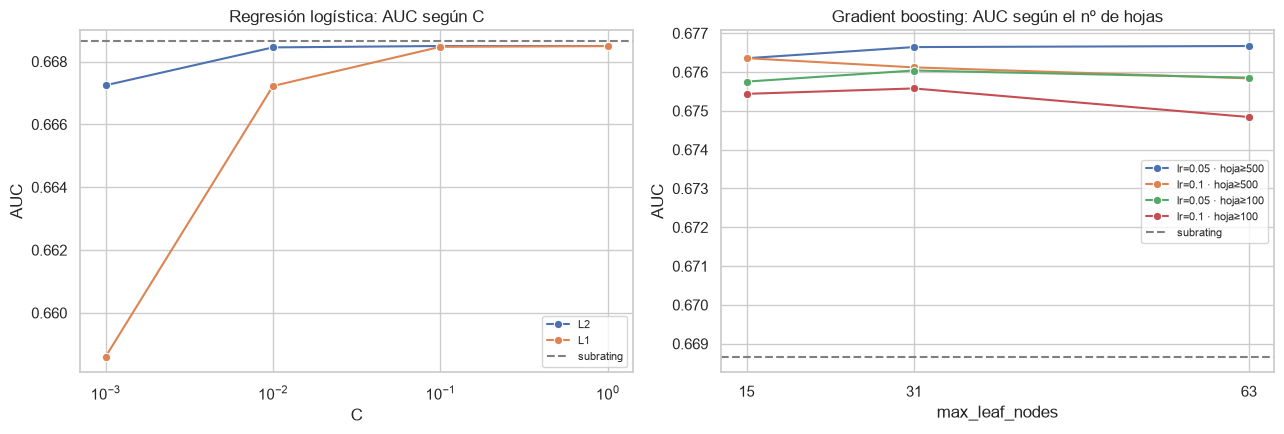

In [45]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5))

# Izquierda: logística, AUC según C para L1 y L2
logistica = resultados[resultados['familia'] == 'LogisticRegression'].copy()
logistica['C'] = logistica['hiperparametros'].str.extract(r'C=([\d.]+)').astype(float)[0]
logistica['regularizacion'] = np.where(logistica['hiperparametros'].str.contains('l1_ratio=1'), 'L1', 'L2')
sns.lineplot(data=logistica, x='C', y='AUC', hue='regularizacion', marker='o', ax=ejes[0])
ejes[0].set_xscale('log')
ejes[0].set_title('Regresión logística: AUC según C')

# Derecha: gradient boosting, AUC según el tamaño del árbol para cada learning_rate y min_samples_leaf
boosting = resultados[resultados['familia'] == 'HistGradientBoosting'].copy()
for parametro in ['learning_rate', 'max_leaf_nodes', 'min_samples_leaf']:
    boosting[parametro] = boosting['hiperparametros'].str.extract(parametro + r'=([\d.]+)').astype(float)[0]
boosting['combinacion'] = ('lr=' + boosting['learning_rate'].astype(str)
                           + ' · hoja≥' + boosting['min_samples_leaf'].astype(int).astype(str))
sns.lineplot(data=boosting, x='max_leaf_nodes', y='AUC', hue='combinacion', marker='o', ax=ejes[1])
ejes[1].set_xticks([15, 31, 63])
ejes[1].set_title('Gradient boosting: AUC según el nº de hojas')

for eje in ejes:
    eje.axhline(AUC_SUBRATING, color='grey', linestyle='--', label='subrating')  # listón
    eje.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Qué se hace:** a la izquierda, el AUC de la logística según `C` con L1 y L2; a la derecha, el del *gradient boosting* según el tamaño de los árboles, para cada combinación de `learning_rate` y `min_samples_leaf`. La línea gris es el subrating.

**Qué se observa:**

- **Logística:** a partir de `C` = 0,01 (L2) o 0,1 (L1) el AUC ya no cambia: con 443.000 préstamos casi no hace falta regularizar. Con `C` muy pequeño la L1 elimina demasiadas variables y cae a 0,659. L1 y L2 acaban dando lo mismo.
- ***Gradient boosting*:** la línea azul (`learning_rate` 0,05 y hoja ≥ 500, la combinación más prudente) está siempre arriba, y con ella 31 y 63 hojas empatan (0,6766 y 0,6767). Con las combinaciones menos prudentes, pasar de 31 a 63 hojas empeora el AUC.
- Todas las combinaciones de *gradient boosting* están por encima del subrating; ninguna logística.

<a id="s7"></a>
<div style="background-color:#1f4e79; padding:2px 16px; border-radius:6px; margin-top:16px;">

## <span style="color:#ffffff">7 · ELECCIÓN DEL MODELO (D6)</span>

</div>

El primero de la tabla no tiene por qué ser el elegido: si otro modelo más sencillo está **a menos de un error estándar** del mejor, la diferencia puede ser azar de las particiones. El **error estándar** es la desviación típica del AUC entre las 3 particiones dividida por √3: mide cuánto podría variar el AUC medio solo por cómo se han hecho las particiones.

La **regla de un error estándar** (habitual en validación cruzada) elige, entre los modelos "empatados" con el mejor, el más sencillo: primero la familia lineal y, dentro de cada familia, el de mayor AUC.

In [46]:
# Umbral: AUC del mejor menos su error estándar (desviación típica entre particiones / √nº de particiones)
mejor = resultados.iloc[0]
error_estandar = mejor['AUC_std'] / np.sqrt(PARTICIONES.get_n_splits())
umbral = mejor['AUC'] - error_estandar

# Candidatos empatados con el mejor y, entre ellos, el más sencillo
empatados = resultados[resultados['AUC'] >= umbral]
elegido = empatados.sort_values(['complejidad', 'AUC'], ascending=[True, False]).iloc[0]

print(f"Mejor AUC: {mejor['AUC']:.4f} · error estándar {error_estandar:.4f} → umbral {umbral:.4f}")
print(f"Combinaciones empatadas con el mejor: {len(empatados)} ({', '.join(empatados['familia'].unique())})")
print(f"Elegido: {elegido['familia']} · {elegido['hiperparametros']} · AUC {elegido['AUC']:.4f}")

# Parámetros del elegido (tipo de modelo e hiperparámetros), para reconstruir su pipeline en las secciones 8 a 10
PARAMETROS_ELEGIDO = busqueda.cv_results_['params'][elegido['indice']]

Mejor AUC: 0.6767 · error estándar 0.0010 → umbral 0.6757
Combinaciones empatadas con el mejor: 9 (HistGradientBoosting)
Elegido: HistGradientBoosting · learning_rate=0.05, max_leaf_nodes=63, min_samples_leaf=500 · AUC 0.6767


**Qué se hace:** se calcula el umbral (AUC del mejor menos su error estándar), se buscan las combinaciones que lo superan y se elige la más sencilla. Se guardan sus parámetros para reconstruir el modelo.

**Qué se observa:** el umbral es **0,6757** (0,6767 − 0,0010). Las 9 combinaciones empatadas son todas *gradient boosting*: la mejor logística (0,6685) queda muy lejos, a unos 8 errores estándar. Se elige el **mejor *gradient boosting*** (`learning_rate` 0,05, **63 hojas**, hoja ≥ 500). La versión con 31 hojas (0,6766), la elegida en la ejecución anterior, está prácticamente empatada: la regla solo ordena por familia, no por tamaño del árbol.

> **Decisión D6 · Elegir con la regla de un error estándar.**
> - **Por qué esta regla:** evita elegir un modelo más complejo por una diferencia que puede ser azar. Es la regla habitual en validación cruzada (Hastie, Tibshirani y Friedman).
> - **Resultado:** gana el *gradient boosting* porque su ventaja (+0,008 de AUC) es clara, no por azar.
> - **Lo que se pierde:** la logística se explica con un coeficiente por variable, y en banca suele preferirse por eso. Aquí se compensa con la importancia por permutación y la dependencia parcial (secciones 9.3 y 9.4).
> - **Alternativa:** quedarse con la logística, que iguala al subrating y es más fácil de explicar, a cambio de 0,008 de AUC.

<a id="s8"></a>
<div style="background-color:#1f4e79; padding:2px 16px; border-radius:6px; margin-top:16px;">

## <span style="color:#ffffff">8 · ¿HACE FALTA `sector_empleo`? (D7)</span>

</div>

En el notebook 03 (D20) se vio que `sector_empleo` es **inestable**: hasta finales de 2013 el campo original era el nombre de la empresa y no el puesto, y el 59 % de esos préstamos acabó en "otros" (PSI 0,988 entre 2012 y 2015). Además, es la variable con más carga ética (D5 del notebook 03). Se comprueba cuánto aporta al modelo elegido.

In [47]:
def auc_validacion_cruzada(categoricas, numericas):
    """AUC medio (y su desviación) del modelo elegido con las variables indicadas."""
    pipeline = crear_pipeline(LogisticRegression(), categoricas, numericas, PARAMETROS_ELEGIDO)
    # Se pasan las columnas originales: el ColumnTransformer elige después qué variables usa
    r = cross_validate(pipeline, X, y, cv=PARTICIONES, scoring='roc_auc', n_jobs=-1)
    return r['test_score'].mean(), r['test_score'].std()

CATEGORICAS_SIN_SECTOR = [c for c in CATEGORICAS if c != 'sector_empleo']
comparacion_sector = pd.DataFrame(
    [auc_validacion_cruzada(CATEGORICAS, NUMERICAS), auc_validacion_cruzada(CATEGORICAS_SIN_SECTOR, NUMERICAS)],
    index=['con sector_empleo', 'sin sector_empleo'], columns=['AUC', 'AUC_std'])
comparacion_sector['diferencia'] = comparacion_sector['AUC'] - comparacion_sector.loc['con sector_empleo', 'AUC']
comparacion_sector

,AUC,AUC_std,diferencia
con sector_empleo,0.6767,0.0017,0.0000
sin sector_empleo,0.6735,0.0014,-0.0032


**Qué se hace:** se repite la validación cruzada del modelo elegido con y sin `sector_empleo`.

**Qué se observa:** **quitar `sector_empleo` baja el AUC de 0,6767 a 0,6735** (−0,003). Es una pérdida pequeña pero real: unas tres veces su error estándar (0,001).

> **Decisión D7 · Mantener `sector_empleo` en el modelo.**
> - **Por qué:** aporta 0,003 de AUC, más que el azar de las particiones (regla de la sección 7).
> - **El riesgo de inestabilidad es asumible:** en la API llegará con la definición actual (el puesto, no la empresa), que es la de la mayoría de los datos de entrenamiento (2014–2015).
> - **Nota ética** (notebook 03, D5): el sector no es una característica protegida, pero se debe vigilar que no actúe como sustituto de una (por ejemplo, del sexo en sectores muy masculinizados o feminizados).
> - **Alternativa:** quitarla para tener un modelo más estable y sin esa duda ética, perdiendo 0,003 de AUC (seguiría por encima del subrating).

In [48]:
# Variables definitivas del modelo según D7: se mantiene sector_empleo solo si quitarlo
# hace perder más AUC que un error estándar (misma regla que en la sección 7)
perdida_sin_sector = -comparacion_sector.loc['sin sector_empleo', 'diferencia']
error_estandar_sector = comparacion_sector.loc['con sector_empleo', 'AUC_std'] / np.sqrt(PARTICIONES.get_n_splits())
CATEGORICAS_MODELO = CATEGORICAS if perdida_sin_sector > error_estandar_sector else CATEGORICAS_SIN_SECTOR
NUMERICAS_MODELO = NUMERICAS
VARIABLES_MODELO = CATEGORICAS_MODELO + NUMERICAS_MODELO
print(f"Variables del modelo: {len(VARIABLES_MODELO)} → {VARIABLES_MODELO}")

Variables del modelo: 15 → ['antigüedad_empleo', 'vivienda', 'finalidad', 'sector_empleo', 'num_cuotas', 'ingresos', 'dti', 'fico', 'num_lineas_credito', 'num_hipotecas', 'saldo_revolving', 'porc_uso_tarjetas', 'num_consultas_6meses', 'ratio_principal_ingresos', 'antiguedad_historial']


**Qué se hace:** se fijan las variables definitivas del modelo según D7.

**Qué se observa:** se mantienen las **15 variables**, incluida `sector_empleo`.

<a id="s9"></a>
<div style="background-color:#1f4e79; padding:2px 16px; border-radius:6px; margin-top:16px;">

## <span style="color:#ffffff">9 · ANÁLISIS DEL MODELO ELEGIDO</span>

</div>

Para analizar el modelo sin hacer trampa se usan **predicciones fuera de partición**: cada préstamo recibe la predicción del modelo entrenado con las otras dos particiones, el que **no lo ha visto**. Así se tiene una predicción "honesta" para los 443.000 préstamos.

In [49]:
# Pipeline del modelo elegido con las variables definitivas
pipeline_elegido = crear_pipeline(LogisticRegression(), CATEGORICAS_MODELO, NUMERICAS_MODELO, PARAMETROS_ELEGIDO)

# Probabilidad de impago fuera de partición (columna 1 = clase "impago")
pd_oof = cross_val_predict(pipeline_elegido, X, y, cv=PARTICIONES, method='predict_proba', n_jobs=-1)[:, 1]
print(f"Predicciones fuera de partición: {len(pd_oof):,} · PD media {pd_oof.mean():.2%} (real {y.mean():.2%})")

Predicciones fuera de partición: 443,405 · PD media 14.84% (real 14.85%)


**Qué se hace:** se reconstruye el *pipeline* elegido y se obtiene, para cada préstamo, la probabilidad de impago predicha por el modelo que no lo vio al entrenar.

**Qué se observa:** la PD media predicha (**14,84 %**) es prácticamente igual a la tasa real (**14,85 %**): el modelo no tiene sesgo global.

<a id="s9-1"></a>

### 9.1 · Discriminación: AUC, Gini y KS

Tres formas de medir lo bien que el modelo **separa** a buenos y malos pagadores:
- **AUC:** explicado en la sección 3.
- **Gini** = 2 × AUC − 1: la misma información en escala 0–1 (0 es azar). Es la que más se usa en banca.
- **KS** (Kolmogorov-Smirnov): la mayor distancia entre la proporción acumulada de impagados y de pagados al recorrer la puntuación. Cuanto mayor, mejor separa.

,AUC,Gini,KS
modelo elegido,0.6767,0.3533,0.2563
subrating,0.6687,0.3373,0.2484


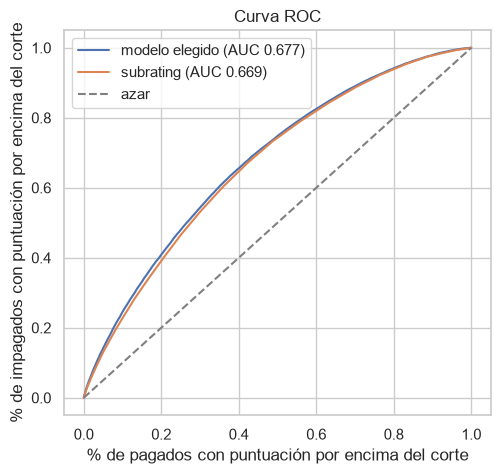

In [50]:
def discriminacion(y_real, puntuacion):
    """AUC, Gini y KS de una puntuación de riesgo."""
    auc = roc_auc_score(y_real, puntuacion)
    fpr, tpr, _ = roc_curve(y_real, puntuacion)   # tasas acumuladas de pagados (fpr) e impagados (tpr)
    return {'AUC': auc, 'Gini': 2 * auc - 1, 'KS': np.max(tpr - fpr)}

tabla_discriminacion = pd.DataFrame({
    'modelo elegido': discriminacion(y, pd_oof),
    'subrating': discriminacion(y, puntuacion_subrating),
}).T
display(tabla_discriminacion)

# Curva ROC de los dos
fig, eje = plt.subplots(figsize=(5.5, 5))
for nombre, puntuacion in [('modelo elegido', pd_oof), ('subrating', puntuacion_subrating)]:
    fpr, tpr, _ = roc_curve(y, puntuacion)
    eje.plot(fpr, tpr, label=f"{nombre} (AUC {roc_auc_score(y, puntuacion):.3f})")
eje.plot([0, 1], [0, 1], color='grey', linestyle='--', label='azar')
eje.set_xlabel('% de pagados con puntuación por encima del corte')
eje.set_ylabel('% de impagados con puntuación por encima del corte')
eje.set_title('Curva ROC')
eje.legend()
plt.show()

**Qué se hace:** AUC, Gini y KS del modelo (con predicciones fuera de partición) y del subrating, y sus curvas ROC. Cada punto de la curva es un posible corte: cuántos impagados se detectan (eje vertical) a cambio de cuántos buenos clientes se rechazan (eje horizontal).

**Qué se observa:** el modelo **supera al subrating en las tres medidas**: AUC **0,6767** frente a 0,6687, Gini **0,353** frente a 0,337 y KS **0,256** frente a 0,248. Las dos curvas ROC están muy juntas; la del modelo queda un poco por encima en casi todo el recorrido. Es un nivel de discriminación moderado, típico de los modelos de admisión con pocos datos del cliente.

<a id="s9-2"></a>

### 9.2 · Calibración (D8)

Se agrupan los préstamos en 10 tramos (deciles) según la PD predicha y se compara, en cada tramo, la **PD media predicha** con la **tasa real de impago**. Si el modelo está bien calibrado, los puntos caen sobre la diagonal.

,n,pd_predicha,tasa_real,diferencia
decil,,,,
1,44341,0.0398,0.0366,0.0031
2,44340,0.0669,0.0665,0.0005
3,44341,0.0872,0.0865,0.0007
4,44340,0.1060,0.1073,-0.0014
5,44341,0.1248,0.1263,-0.0015
6,44340,0.1452,0.1454,-0.0001
7,44340,0.1684,0.1747,-0.0064
8,44341,0.1961,0.1988,-0.0026
9,44340,0.2341,0.2328,0.0013


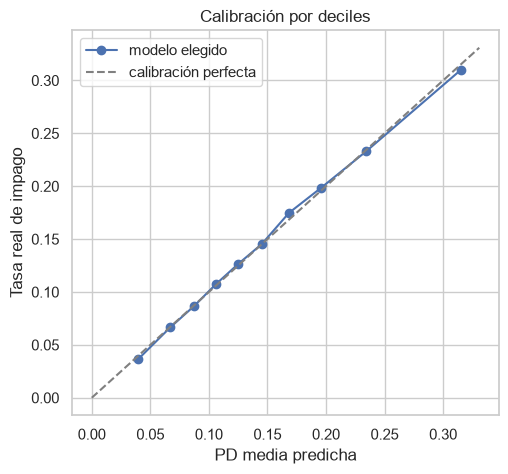

In [51]:
# Deciles de PD predicha: el 1 tiene el 10 % de préstamos con menos riesgo y el 10 el de más riesgo
deciles = pd.qcut(pd_oof, 10, labels=range(1, 11))
calibracion = pd.DataFrame({'pd_predicha': pd_oof, 'impago': y.values, 'decil': deciles}).groupby('decil', observed=True).agg(
    n=('impago', 'size'),
    pd_predicha=('pd_predicha', 'mean'),
    tasa_real=('impago', 'mean'),
)
calibracion['diferencia'] = calibracion['pd_predicha'] - calibracion['tasa_real']
display(calibracion)

fig, eje = plt.subplots(figsize=(5.5, 5))
eje.plot(calibracion['pd_predicha'], calibracion['tasa_real'], marker='o', label='modelo elegido')
limite = calibracion[['pd_predicha', 'tasa_real']].max().max() * 1.05
eje.plot([0, limite], [0, limite], color='grey', linestyle='--', label='calibración perfecta')
eje.set_xlabel('PD media predicha')
eje.set_ylabel('Tasa real de impago')
eje.set_title('Calibración por deciles')
eje.legend()
plt.show()

**Qué se hace:** tabla y gráfico de calibración por deciles de PD predicha.

**Qué se observa:** 
- La **PD predicha y la tasa real coinciden en todos los deciles**: la mayor diferencia es de 0,6 puntos (decil 7: 16,8 % frente a 17,5 %).
- El modelo **ordena bien el riesgo**: la tasa real de impago va del **3,7 %** en el decil 1 al **31,0 %** en el decil 10. El 10 % más arriesgado impaga 8 veces más que el 10 % más seguro.

> **Decisión D8 · No recalibrar las probabilidades.**
> - **Por qué:** el *gradient boosting* se entrena minimizando el *log-loss*, que ya produce probabilidades calibradas, y la tabla lo confirma.
> - **Alternativa descartada:** recalibrar con `CalibratedClassifierCV` (isotónica o Platt). Añadiría un paso más al modelo sin ninguna mejora visible.
> - **A vigilar en la validación final:** que la calibración se mantenga en el conjunto de validación.

<a id="s9-3"></a>

### 9.3 · Importancia de las variables

La **importancia por permutación** mide cuánto empeora el AUC si se **desordena** una variable al azar (se rompe su relación con el impago y el resto queda igual). Si el AUC cae mucho, el modelo depende mucho de esa variable. Funciona con cualquier modelo y se calcula sobre las **15 variables preparadas** (no sobre las columnas originales ni sobre las del *one-hot*): se aplica la preparación a la muestra y se desordena cada variable antes del preprocesado.

Se entrena con dos particiones y se mide en la tercera (una muestra de 50.000 préstamos, para que no tarde demasiado).

,caida_AUC,desviacion
fico,0.0456,0.0006
ratio_principal_ingresos,0.0221,0.0014
num_cuotas,0.0157,0.0003
dti,0.0124,0.0004
saldo_revolving,0.0123,0.0002
num_consultas_6meses,0.0107,0.0012
sector_empleo,0.0085,0.0008
finalidad,0.0079,0.0005
ingresos,0.0068,0.0005
num_lineas_credito,0.0053,0.0005


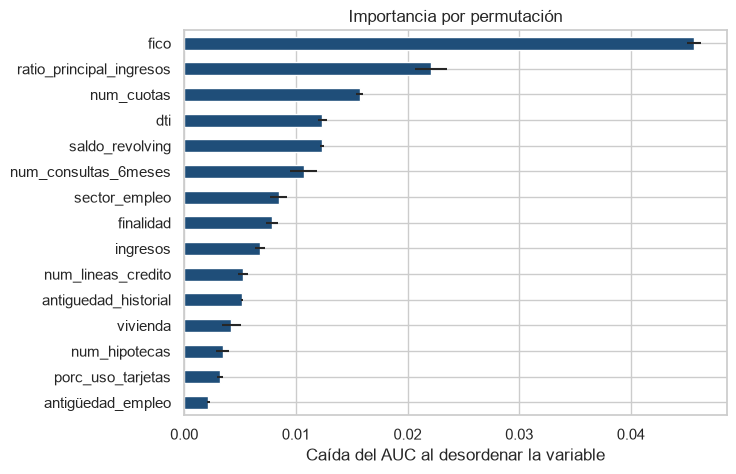

In [52]:
# Primera partición: índices de entrenamiento y de evaluación
indices_entreno, indices_evaluacion = next(PARTICIONES.split(X, y))
modelo_particion = pipeline_elegido.fit(X.iloc[indices_entreno], y.iloc[indices_entreno])

# El pipeline se divide en dos: [:1] = preparación · [1:] = preprocesado + modelo
preparacion_particion = modelo_particion[:1]
modelo_sin_preparacion = modelo_particion[1:]

# Muestra de 50.000 préstamos de la parte de evaluación, ya preparada (15 variables del modelo)
muestra_original = X.iloc[indices_evaluacion].sample(50_000, random_state=42)
muestra = preparacion_particion.transform(muestra_original)[VARIABLES_MODELO]
y_muestra = y.loc[muestra.index]

# Cada variable preparada se desordena 3 veces y se mide la caída media del AUC
importancia = permutation_importance(modelo_sin_preparacion, muestra, y_muestra, scoring='roc_auc',
                                     n_repeats=3, random_state=42, n_jobs=-1)
tabla_importancia = pd.DataFrame({
    'caida_AUC': importancia.importances_mean,
    'desviacion': importancia.importances_std,
}, index=VARIABLES_MODELO).sort_values('caida_AUC', ascending=False)
display(tabla_importancia)

fig, eje = plt.subplots(figsize=(7, 5))
tabla_importancia['caida_AUC'][::-1].plot.barh(xerr=tabla_importancia['desviacion'][::-1], ax=eje, color='#1f4e79')
eje.set_xlabel('Caída del AUC al desordenar la variable')
eje.set_title('Importancia por permutación')
plt.show()

**Qué se hace:** se entrena el modelo con dos particiones y se calcula, en una muestra de la tercera, la caída del AUC al desordenar cada variable.

**Qué se observa:** 
- El **FICO** es con diferencia la variable más importante: desordenarlo baja el AUC en 0,046.
- Le siguen el **ratio importe / ingresos** (0,022), el **plazo** (0,016), el **DTI** (0,012), el **saldo revolving** (0,012) y las **consultas** de los últimos 6 meses (0,011). Las dos variables creadas en el notebook 04 aportan: el ratio es la segunda más importante.
- `sector_empleo` (0,0085) y `finalidad` (0,008) son las categóricas que más aportan. La que menos, `antigüedad_empleo` (0,002).
- Coincide con la comprobación rápida del EDA (notebook 03, sección 11): el FICO y el plazo ya eran las que más aportaban.

<a id="s9-4"></a>

### 9.4 · Sentido de las variables

La **dependencia parcial** muestra cómo cambia la PD media predicha al mover **una** variable y dejar el resto como está. Sirve para comprobar que el modelo tiene sentido de negocio (por ejemplo, que a más FICO, menos riesgo).

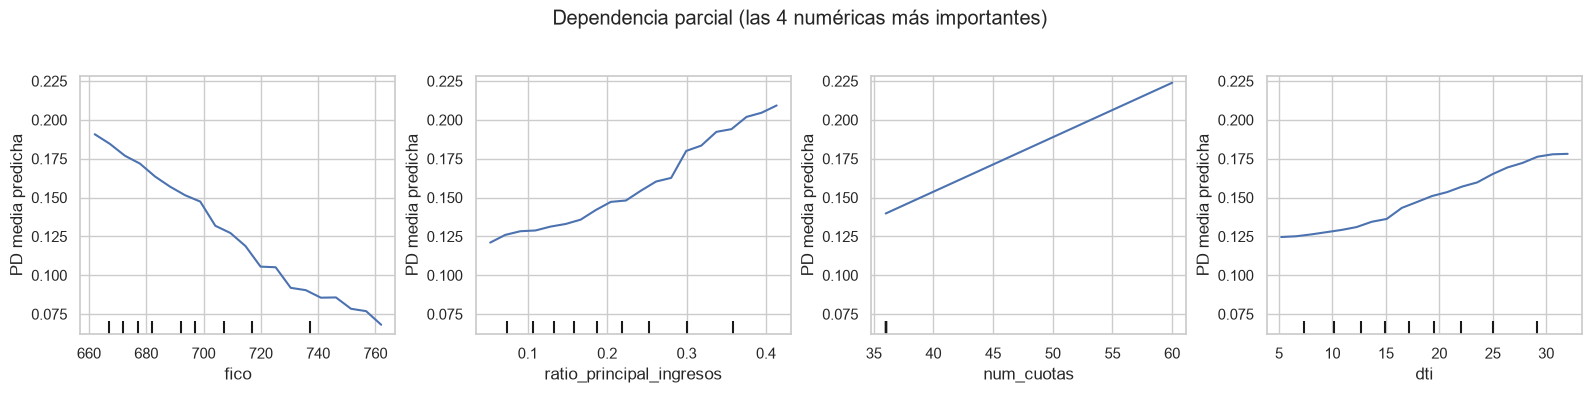

In [53]:
# Dependencia parcial de las 4 numéricas más importantes, en una muestra de 5.000 préstamos
VARIABLES_SENTIDO = [v for v in tabla_importancia.index if v in NUMERICAS_MODELO][:4]
fig, ejes = plt.subplots(1, 4, figsize=(16, 3.8))
PartialDependenceDisplay.from_estimator(
    # Sobre las variables preparadas (en su escala: con logaritmos y recortes), igual que la importancia
    modelo_sin_preparacion, muestra.sample(5_000, random_state=42), VARIABLES_SENTIDO,
    response_method='predict_proba', grid_resolution=20, ax=ejes)
for eje in ejes:
    eje.set_ylabel('PD media predicha')
plt.suptitle('Dependencia parcial (las 4 numéricas más importantes)', y=1.03)
plt.tight_layout()
plt.show()

**Qué se hace:** dependencia parcial de las cuatro variables numéricas más importantes. Recuerda que `ingresos`, `num_hipotecas` y `antiguedad_historial` están en logaritmo (notebook 04, D8).

**Qué se observa:** las cuatro tienen **sentido de negocio**:
- **FICO:** la PD baja de forma continua, del 19 % con 660 al 7 % con 760.
- **Ratio importe / ingresos:** la PD sube del 12 % al 21 % cuanto mayor es el préstamo respecto a los ingresos.
- **Plazo:** con 60 cuotas la PD sube del 14 % al 22 %. Solo hay dos valores (36 y 60), por eso la línea es recta entre ellos.
- **DTI:** a más endeudamiento, más riesgo (del 12,5 % al 18 %).

<a id="s10"></a>
<div style="background-color:#1f4e79; padding:2px 16px; border-radius:6px; margin-top:16px;">

## <span style="color:#ffffff">10 · ENTRENAR Y GUARDAR EL MODELO FINAL (D9)</span>

</div>

In [54]:
# Entrenar el pipeline elegido con TODO el conjunto de entrenamiento (sin caché: el modelo guardado no debe depender de ella)
modelo_final = crear_pipeline(LogisticRegression(), CATEGORICAS_MODELO, NUMERICAS_MODELO, PARAMETROS_ELEGIDO, cache=None)
modelo_final.fit(X, y)

# Paquete que se guarda: el modelo y todo lo necesario para usarlo y evaluarlo después
paquete_pd = {
    'modelo': modelo_final,                         # pipeline completo (preparación + preprocesado + modelo)
    'columnas_entrada': COLUMNAS_ENTRADA,           # columnas originales que acepta el pipeline
    'variables': VARIABLES_MODELO,                  # variables que usa el modelo tras la preparación
    'categoricas': CATEGORICAS_MODELO,
    'numericas': NUMERICAS_MODELO,
    'hiperparametros': elegido['hiperparametros'],
    'familia': elegido['familia'],
    'metricas_validacion_cruzada': {**tabla_discriminacion.loc['modelo elegido'].to_dict(),
                                    'log_loss': log_loss(y, pd_oof), 'Brier': brier_score_loss(y, pd_oof)},
    'auc_subrating': AUC_SUBRATING,
    'version_sklearn': sklearn.__version__,         # un modelo guardado solo es seguro con la misma versión
    'version_pandas': pd.__version__,
}

# cloudpickle guarda el CÓDIGO de preparacion.py dentro del archivo (no solo su nombre):
# así la API puede cargar el modelo sin tener una copia de 04_scripts/
cloudpickle.register_pickle_by_value(preparacion)
RUTA_MODELOS.mkdir(exist_ok=True)                   # crea 05_modelos/ si no existe
ARCHIVO_MODELO = RUTA_MODELOS / 'modelo_pd.pkl'
with open(ARCHIVO_MODELO, 'wb') as archivo:
    cloudpickle.dump(paquete_pd, archivo)

# Comprobación: se vuelve a cargar y predice lo mismo que el modelo en memoria
with open(ARCHIVO_MODELO, 'rb') as archivo:
    recargado = cloudpickle.load(archivo)
assert np.allclose(recargado['modelo'].predict_proba(X.head(1000))[:, 1],
                   modelo_final.predict_proba(X.head(1000))[:, 1])
print(f"✅ modelo_pd.pkl guardado en {RUTA_MODELOS} ({ARCHIVO_MODELO.stat().st_size / 1e6:.1f} MB)")
print({k: round(v, 4) for k, v in paquete_pd['metricas_validacion_cruzada'].items()})

# La caché de la búsqueda ya no hace falta: se borra la carpeta temporal
shutil.rmtree(CACHE, ignore_errors=True)

✅ modelo_pd.pkl guardado en ..\..\05_modelos (1.5 MB)
{'AUC': 0.6767, 'Gini': 0.3533, 'KS': 0.2563, 'log_loss': 0.3947, 'Brier': 0.12}


**Qué se hace:** se entrena el *pipeline* elegido con los 443.405 préstamos de entrenamiento y se guarda junto con sus variables, hiperparámetros, métricas de validación cruzada y versiones de `scikit-learn` y `pandas`. Se comprueba que el archivo guardado predice lo mismo y se borra la caché.

**Qué se observa:** el modelo queda en `05_modelos/modelo_pd.pkl` (**1,5 MB**, con el código de la preparación dentro) con AUC 0,6767, Gini 0,353, KS 0,256, *log-loss* 0,3947 y Brier 0,1200 en validación cruzada.

> **Decisión D9 · Guardar el modelo en `05_modelos/modelo_pd.pkl` con `cloudpickle`, como un paquete con el *pipeline* y sus metadatos.**
> - **Por qué `cloudpickle`:** `joblib` y `pickle` guardan la clase `PreparacionScoring` solo por su nombre, así que la API necesitaría una copia de `preparacion.py`. Con `register_pickle_by_value`, `cloudpickle` mete el código dentro del archivo y la API solo necesita el `.pkl` (es lo que ya hacía la API actual). El archivo se abre con `pickle.load` normal.
> - **Lo que no resuelve:** la versión de `scikit-learn` tiene que ser la misma al guardar y al cargar; por eso se guarda en el paquete.
> - **Por qué un paquete y no solo el modelo:** la validación final y la API necesitan saber qué variables espera y con qué versión se entrenó.
> - **Los modelos no se suben a GitHub** si pesan mucho; se pueden regenerar ejecutando este notebook.

<a id="s11"></a>
<div style="background-color:#1f4e79; padding:2px 16px; border-radius:6px; margin-top:16px;">

## <span style="color:#ffffff">11 · RESUMEN Y PRÓXIMOS PASOS</span>

</div>

**Qué se ha hecho** (detalle en el registro de decisiones del principio):

| Bloque | Decisiones | Resultado |
|---|---|---|
| **Listón** | D1 | Subrating de Lending Club: AUC 0,6687 |
| ***Pipeline* y validación** | D2–D4 | Preparación (`preparacion.py`) + *one-hot* + estandarización + modelo; 3 particiones; AUC para elegir |
| **Búsqueda** | D5 | 8 logísticas y 12 *gradient boosting* en unos 16 minutos |
| **Elección** | D6–D8 | *Gradient boosting* (`learning_rate` 0,05, 63 hojas, hoja ≥ 500), con `sector_empleo` y sin recalibrar |
| **Guardado** | D9 | `05_modelos/modelo_pd.pkl` (con `cloudpickle`) |

**Hallazgos principales:**
- El modelo **supera al subrating de Lending Club** (AUC 0,6767 frente a 0,6687) usando solo los datos del formulario, sin el tipo de interés.
- La **logística solo empata con el subrating** (0,6685): los árboles ganan 0,008 de AUC porque captan relaciones no lineales e interacciones.
- Está **bien calibrado**: la PD predicha coincide con la tasa real en cada decil (del 3,7 % al 31 %).
- El **FICO**, el **ratio importe / ingresos** y el **plazo** son las variables que más pesan, y todas tienen el sentido esperado.
- El modelo guardado recibe los datos **originales** (o los del formulario de la API) y hace él mismo toda la preparación.

**Próximos pasos:**
1. **06 · EAD** y **07 · LGD**, con el mismo *pipeline* y la misma regla de elección.
2. **08 · Validación final** de los tres modelos con el conjunto de validación, que hasta ahora no se ha tocado.
3. **Nueva API** con los tres modelos.